# 03 · Distributions and Relationship with the Target

**Objective:** describe how each variable in the dataset is distributed and how it relates to the
target `is_canceled`, in order to identify which variables are useful for predicting booking
cancellations and which transformations they will need before modelling (encoding, binning, scaling).

**Scope:**
- Includes: variable inventory and data types, class balance of the target, distributions of
  numerical and categorical variables, cancellation rate by variable, and a preliminary selection of
  useful variables, including a check for variables not available at booking time (data leakage).
- Does not include: duplicates, missing and erroneous values (→ `01_cleaning`), or outlier
  detection and treatment (→ `02_outliers`).

**Data:** the clean dataset produced by `01_cleaning` (`data/hotels_clean.csv`, 86,622 bookings ×
32 columns, after removing duplicates and invalid rows). Run `01_cleaning` first to create it.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


In [10]:
csv_path = "../data/hotels_clean.csv"   # created by 01_cleaning.ipynb (run it first)
df = pd.read_csv(csv_path)
df.shape

(86622, 32)

In [11]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,No agent,No company,0,Transient,75.0,0,0,Check-Out,2015-07-02
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,No company,0,Transient,75.0,0,0,Check-Out,2015-07-02
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,No company,0,Transient,98.0,0,1,Check-Out,2015-07-03
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,No agent,No company,0,Transient,107.0,0,0,Check-Out,2015-07-03
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303,No company,0,Transient,103.0,0,1,Check-Out,2015-07-03


In [12]:
inventory = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "example": df.iloc[0],
})
inventory

,dtype,n_unique,n_missing,example
hotel,str,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,478,0,7
arrival_date_year,int64,3,0,2015
arrival_date_month,str,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,33,0,1
adults,int64,7,0,1


In [13]:
target = "is_canceled"
numerical_continuous = ["adr", "lead_time", "days_in_waiting_list"]
numerical_counts = ["adults", "children", "babies", "previous_cancellations","previous_bookings_not_canceled", "booking_changes", "required_car_parking_spaces", "total_of_special_requests", "stays_in_weekend_nights", "stays_in_week_nights"]
binary = ["is_repeated_guest"]
categorical = ["meal", "hotel", "deposit_type", "reserved_room_type", "assigned_room_type", "customer_type", "market_segment", "distribution_channel", "country"]
id_codes = ["agent", "company"]
date_parts = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"]
leakage = ["reservation_status", "reservation_status_date"]

In [14]:
all_columns = [target] + numerical_continuous + numerical_counts + binary + categorical + id_codes + date_parts + leakage

print(len(all_columns), "assigned |", len(df.columns), "in the dataset")
print("Every column assigned exactly once: ", sorted(all_columns) == sorted(df.columns))

32 assigned | 32 in the dataset
Every column assigned exactly once:  True


In [15]:
counts = df[target].value_counts()
proportions = df[target].value_counts(normalize=True)
pd.DataFrame({"count": counts, "proportion": proportions.round(3)})

,count,proportion
is_canceled,,
0,62650,0.723
1,23972,0.277


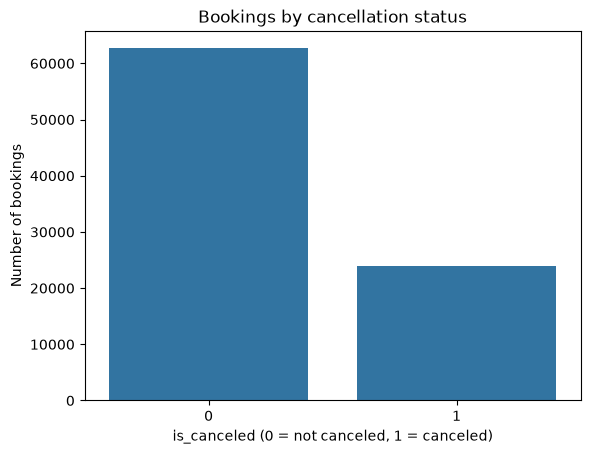

In [16]:
sns.countplot(data=df, x=target)
plt.title("Bookings by cancellation status")
plt.xlabel("is_canceled (0 = not canceled, 1 = canceled)")
plt.ylabel("Number of bookings")
plt.show()

### Conclusions and actions: variable inventory

**Conclusions**
- After cleaning, the dataset has 86,622 bookings and 32 columns. It started with 119,390;
  `01_cleaning` removed the duplicates and the invalid rows. There are no missing values left.
- Sorting the columns by what they mean gives: 1 target, 3 continuous, 10 counts, 1 binary,
  9 categorical, 2 ID codes, 4 parts of the arrival date and 2 leakage columns.
- The type pandas gives a column doesn't always match what it means:
  - `is_canceled` and `is_repeated_guest` look like numbers, but they are just yes/no (0/1).
  - `agent` and `company` are codes, not quantities: agent 240 isn't "more" than agent 9. In the raw
    file they were `float` because of the `NULL` values; `01_cleaning` replaced those with
    "No agent" / "No company", so they are now text.
  - `arrival_date_month` and `reservation_status_date` are stored as text, not as dates.
- `reservation_status` gives away the answer: every Canceled (22,973) and No-Show (999) booking has
  `is_canceled = 1`, and every Check-Out (62,650) has `is_canceled = 0`. `reservation_status_date`
  is the date of that final status. Both are only known once the booking is over, so they can't be
  used to predict it.

**Actions**
- Use a different analysis for each group: histograms and boxplots for continuous variables, bar
  charts for counts, and frequency tables with the cancellation rate per category for the rest.
- Put the months in calendar order before plotting (alphabetically, April would come first).
- Treat `agent` and `company` as categories and never average them. They have hundreds of codes,
  so the rare ones will have to be grouped before modelling.
- Leave `reservation_status` and `reservation_status_date` out of the features and explain why in
  the README. Three more columns (`booking_changes`, `assigned_room_type`, `days_in_waiting_list`)
  might also only be known after booking; we keep them for now and check them in the leakage section.